In [ ]:
!pip install gudhi
!pip install gdown
!pip install seaborn
!pip install POT

## Imports and Hyperparameters

In [1]:
import os, pickle, math, random, itertools
import numpy as np
import matplotlib.pyplot as plt
from sklearn.manifold import MDS
import seaborn as sns
import gdown
import ot
import torch
from collections import defaultdict
import pandas as pd

from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.model_selection import StratifiedKFold, cross_validate
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
from sklearn.svm import SVC
from sklearn.metrics import make_scorer, accuracy_score, f1_score
from tqdm import tqdm
from gudhi import RipsComplex

In [30]:
# ----------------------------
# 0) Repro + basic config
# ----------------------------
SEED = 42
rng = np.random.default_rng(SEED)
torch.manual_seed(SEED)
np.random.seed(SEED)
random.seed(SEED)

# Persistence image settings
GRID_BINS = (16, 16)   # (birth_bins, persistence_bins)
SIGMA = 0.02           # Gaussian bandwidth in (birth, persistence) space
USE_DIMS = (0,1)      # compute H0 and H1 by default (# change 0,0 for H0 and 1,1 for H1)
SUBSAMPLE_CELLS = 2000 # for tractability per PDO; set None to disable


## Loading PDO Pointclouds

In [4]:

url = 'https://drive.google.com/drive/folders/1ZiCQDdxftIFzrkiRaP48IftA42gT28HV?usp=share_link'
gdown.download_folder(url, quiet=False)

with open('pdo_data/pc_pdo_treatment.pkl', 'rb') as handle:
    PCs_raw = pickle.load(handle)  # list of arrays, each [num_cells, num_PCs]

# Standardize each PDO’s PC matrix independently (cells × PCs)
PCs = [StandardScaler().fit_transform(arr) for arr in PCs_raw]

# Keep only sufficiently large point clouds for robust homology
keep = [i for i in range(len(PCs)) if PCs[i].shape[0] > 200]

labels = np.load('pdo_data/labels_pdo_treatment.npy')
le = LabelEncoder()
labels_enc = le.fit_transform(labels)

X_clouds = [PCs[i] for i in keep]            # list: each item is [cells_i, d]
y = np.array([labels_enc[i] for i in keep])  # sample-level labels

print(f"#PDOs kept: {len(X_clouds)} | classes: {dict(zip(le.classes_, range(len(le.classes_))))}")

Retrieving folder contents


Processing file 1v21XcNbRWPJginkaOMjy06QNOeWvduQc labels_pdo_treatment.npy
Processing file 1B4w0EjtSeANdJQzOHofyG-wJtSq3wM8y pc_pdo_treatment.pkl


Retrieving folder contents completed
Building directory structure
Building directory structure completed
Downloading...
From: https://drive.google.com/uc?id=1v21XcNbRWPJginkaOMjy06QNOeWvduQc
To: /Users/annasu/Library/CloudStorage/OneDrive-YaleUniversity/Year 4/Classes/CPSC 6440/HW/PS3/pdo_data/labels_pdo_treatment.npy
100%|██████████| 27.0k/27.0k [00:00<00:00, 2.39MB/s]
Downloading...
From (original): https://drive.google.com/uc?id=1B4w0EjtSeANdJQzOHofyG-wJtSq3wM8y
From (redirected): https://drive.google.com/uc?id=1B4w0EjtSeANdJQzOHofyG-wJtSq3wM8y&confirm=t&uuid=e893980f-5737-44be-bded-b11507394236
To: /Users/annasu/Library/CloudStorage/OneDrive-YaleUniversity/Year 4/Classes/CPSC 6440/HW/PS3/pdo_data/pc_pdo_treatment.pkl
100%|██████████| 704M/704M [00:19<00:00, 35.6MB/s] 
Download completed


#PDOs kept: 1625 | classes: {'AH': 0, 'C': 1, 'CF': 2, 'CS': 3, 'CSF': 4, 'DMSO': 5, 'F': 6, 'H2O': 7, 'L': 8, 'O': 9, 'S': 10, 'SF': 11, 'V': 12, 'VS': 13}


### Persistence Diagrams and Features

In [6]:

def compute_vr_diagram(points, max_dim=1, max_edge_length=None):
    """
    points: np.ndarray [n, d] (PCA/embedding space of a PDO's cells)

    TODO: Use Gudhi functions to first create a rips complex
    Then to create a simplex tree
    Use the simplex tree to construct a persistence diagram. The pd variable should be a gudhi persistence object.
    
    returns dict: {0: [(b,d),...], 1: [(b,d),...]} finite pairs only
    """
    rc = RipsComplex(points=points, max_edge_length=max_edge_length)
    st = rc.create_simplex_tree(max_dimension=max_dim + 1) # H_n needs up to (n+1)-simplices
    pd = st.persistence()

    diags = {k: [] for k in range(max_dim+1)}
    for dim, pair in pd:
        b, d = pair
        if math.isinf(d):   # drop essential classes for vectorization
            continue
        if dim in diags:
            diags[dim].append((b, d))
    for k in diags:
        diags[k] = np.array(diags[k], dtype=float) if len(diags[k]) else np.zeros((0, 2), float)
    return diags

In [5]:
def _to_birth_persistence(diag):
    """Convert [(birth, death)] → [(birth, persistence)] with persistence=max(d-b, 0)."""
    if diag.size == 0:
        return diag
    out = np.zeros_like(diag)
    #TODO: populate out
    out[:,0] = diag[:,0] # keeps the birth column
    out[:,1] = diag[:,1] - diag[:,0] # replaces death with persistence
    out[:,1] = np.maximum(out[:,1], 0) # replaces negative persistence with 0
    return out

In [7]:
def make_persistence_image(diag_bd, grid_bins=(32, 32), sigma=0.05, clip_p=None, bounds=None):
    """
    Very small, dependency-free persistence image (PI).
    diag_bd: array [(b, d)] or already birth–persistence [(b, p)]
    grid_bins: (B_bins, P_bins)
    sigma: Gaussian bandwidth in normalized (b,p) coords
    clip_p: optional clamp on persistence before normalization
    bounds: ((bmin,bmax),(pmin,pmax)) shared bounds for all samples (recommended)
    returns flattened PI vector of length B_bins*P_bins
    """
    #TODO: flattened PI
    diag_bp = _to_birth_persistence(diag_bd) # convert to birth-persistence

    (bmin, bmax), (pmin, pmax) = bounds # set bounds
    B_bins, P_bins = grid_bins # unpack grid bins
    pi = np.zeros((B_bins, P_bins), dtype=float) # initialize the B_bins*P_bins PI grid
    # Compute bin edges
    b_edges = np.linspace(bmin, bmax, B_bins + 1)
    p_edges = np.linspace(pmin, pmax, P_bins + 1)
    # Compute bin centers
    b_centers = (b_edges[:-1] + b_edges[1:]) / 2
    p_centers = (p_edges[:-1] + p_edges[1:]) / 2
    # Create meshgrid of bin centers
    Bc, Pc = np.meshgrid(b_centers, p_centers, indexing='ij')
    for b, p in diag_bp:
        if clip_p is not None:
            p = min(p, clip_p)
        # Compute Gaussian contribution
        pi += p*np.exp(-((Bc - b) ** 2 + (Pc - p) ** 2) / (2 * sigma ** 2))
    return pi.flatten()


#### Helper functions

In [8]:
def subsample_points(points, n_max=SUBSAMPLE_CELLS, rng=None):
    if (n_max is None) or (points.shape[0] <= n_max):
        return points
    idx = rng.choice(points.shape[0], size=n_max, replace=False)
    return points[idx]

# (Optional) global bounds for PIs so features are comparable across PDOs
def compute_global_bounds(diags_list, dim):
    """diags_list: list of dicts {0: diag0, 1: diag1, ...}; returns shared ((bmin,bmax),(pmin,pmax))."""
    vals = []
    for d in diags_list:
        if dim in d and d[dim].size > 0:
            bp = _to_birth_persistence(d[dim])
            vals.append(bp)
    if not vals:
        return ((0.0, 1.0), (0.0, 1.0))
    M = np.vstack(vals)
    bmin, bmax = M[:, 0].min(), M[:, 0].max()
    pmin, pmax = 0.0, M[:, 1].max()
    if bmax == bmin: bmax = bmin + 1e-6
    if pmax == pmin: pmax = pmin + 1e-6
    return ((float(bmin), float(bmax)), (float(pmin), float(pmax)))

In [9]:
def baseline_features_from_cloud(pc):
    """
    pc: array [n_cells, d] for one PDO
    return: 1D array [2*d] with mean and std per PC dimension
    """
    mean = pc.mean(axis=0)
    std = pc.std(axis=0)
    return np.concatenate([mean, std])

In [41]:
print("Computing persistence diagrams per PDO...")
diags_per_pdo = []
for pc in tqdm(X_clouds):
    pts = subsample_points(pc, SUBSAMPLE_CELLS, rng)
    diags = compute_vr_diagram(pts, max_dim=max(USE_DIMS), max_edge_length = 4) 
    diags_per_pdo.append(diags)

# Shared PI bounds (recommended)
bounds_H0 = compute_global_bounds(diags_per_pdo, 0)
bounds_H1 = compute_global_bounds(diags_per_pdo, 1)

print("Vectorizing (persistence images)...")
feat_list = []
for di in tqdm(diags_per_pdo):
    parts = []
    if 0 in USE_DIMS:
        parts.append(make_persistence_image(di.get(0, np.zeros((0, 2))), GRID_BINS, SIGMA, bounds=bounds_H0))
    if 1 in USE_DIMS:
        parts.append(make_persistence_image(di.get(1, np.zeros((0, 2))), GRID_BINS, SIGMA, bounds=bounds_H1))
    if parts:
        feat = np.concatenate(parts, axis=0).astype(np.float32)
    else:
        feat = np.zeros(GRID_BINS[0]*GRID_BINS[1], dtype=np.float32)
    feat_list.append(feat)

X_feats = np.stack(feat_list)  # [num_PDOs, feat_dim]
print("PI Feature matrix:", X_feats.shape)

X_baseline = np.vstack([baseline_features_from_cloud(pc) for pc in X_clouds])
print("Baseline feature matrix:", X_baseline.shape)

# ----------------------------
# 4) Classifiers + CV evaluation
# ----------------------------
scaler = StandardScaler(with_mean=True, with_std=True)
X_scaled = scaler.fit_transform(X_feats)
X_base_scaled = scaler.fit_transform(X_baseline)

Xsets_scaled = {
    "PI(0D+1D)": X_scaled,
    "Baseline": X_base_scaled
}

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
scoring = {
    "acc": make_scorer(accuracy_score),
    "f1_macro": make_scorer(f1_score, average="macro")
}

models = {
    "LR": LogisticRegression(max_iter=5000, class_weight="balanced", solver="lbfgs"),
    "LinearSVM": SVC(kernel="linear", class_weight="balanced"),
    "RBFSVM": SVC(kernel="rbf", class_weight="balanced", gamma="scale")
}

print("\n5-fold CV on persistence-image features:")
rows = []
for feat_name, X in Xsets_scaled.items():
    print(f"\nFeature set: {feat_name}")
    for name, clf in models.items():
        res = cross_validate(clf, X, y, cv=cv, scoring=scoring, n_jobs=-1, return_train_score=False)
        print(f"{name:10s}  ACC: {res['test_acc'].mean():.3f}±{res['test_acc'].std():.3f}  "
              f"F1(macro): {res['test_f1_macro'].mean():.3f}±{res['test_f1_macro'].std():.3f}")
        
        row = {
            "FeatureSet": feat_name,
            "Model": name,
        }

        # format each metric as mean±std
        for metric_key in scoring.keys():
            scores = res[f"test_{metric_key}"]
            mean = np.mean(scores)
            std = np.std(scores)
            row[metric_key] = f"{mean:.3f}±{std:.3f}"
        
        rows.append(row)

Computing persistence diagrams per PDO...


100%|██████████| 1625/1625 [00:43<00:00, 37.39it/s] 


Vectorizing (persistence images)...


100%|██████████| 1625/1625 [00:01<00:00, 924.38it/s]


PI Feature matrix: (1625, 512)
Baseline feature matrix: (1625, 88)

5-fold CV on persistence-image features:

Feature set: PI(0D+1D)
LR          ACC: 0.126±0.013  F1(macro): 0.094±0.014
LinearSVM   ACC: 0.158±0.018  F1(macro): 0.092±0.017
RBFSVM      ACC: 0.162±0.007  F1(macro): 0.071±0.017

Feature set: Baseline
LR          ACC: 0.151±0.013  F1(macro): 0.125±0.005
LinearSVM   ACC: 0.175±0.014  F1(macro): 0.143±0.015
RBFSVM      ACC: 0.210±0.013  F1(macro): 0.165±0.008



Confusion Matrices on PI(0D+1D) features:


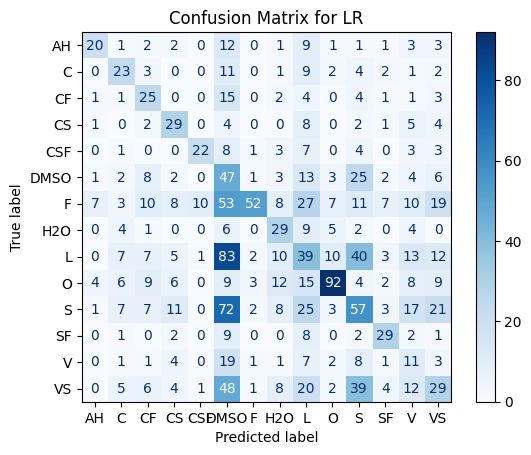

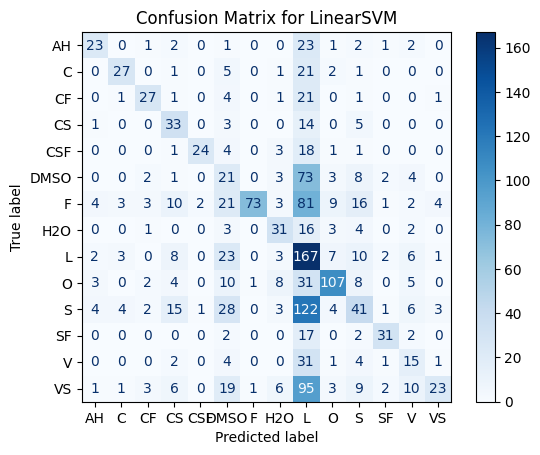

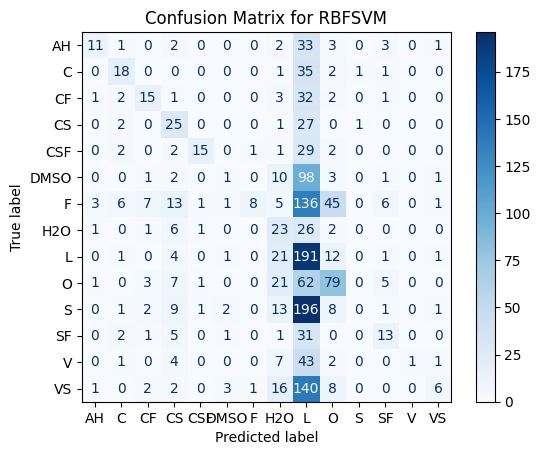

In [42]:
# Plot confusion matrices for each model on PI features
print("\nConfusion Matrices on PI(0D+1D) features:")
for name, clf in models.items():
    clf.fit(X_scaled, y)
    y_pred = clf.predict(X_scaled)

    # Compute confusion matrix
    cm = confusion_matrix(y, y_pred)
    disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=le.classes_)
    disp.plot(cmap=plt.cm.Blues)
    plt.title(f'Confusion Matrix for {name}')
    plt.show()

#### PCA vs PHATE Visualizations for PI Embeddings

Calculating PHATE...
  Running PHATE on 1625 observations and 512 variables.
  Calculating graph and diffusion operator...
    Calculating PCA...
    Calculated PCA in 1.18 seconds.
    Calculating KNN search...
    Calculated KNN search in 0.20 seconds.
    Calculating affinities...
    Calculated affinities in 0.02 seconds.
  Calculated graph and diffusion operator in 1.42 seconds.
  Calculating optimal t...
    Automatically selected t = 8
  Calculated optimal t in 3.05 seconds.
  Calculating diffusion potential...
  Calculated diffusion potential in 0.48 seconds.
  Calculating metric MDS...
  Calculated metric MDS in 2.17 seconds.
Calculated PHATE in 7.14 seconds.
X_pca shape: (1625, 2)
X_phate shape: (1625, 2)


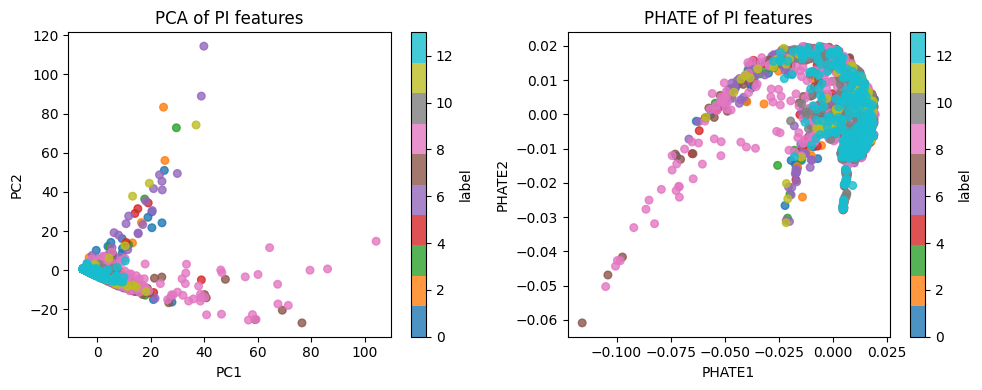

In [43]:
from sklearn.decomposition import PCA
import phate

# PCA embedding 
pca = PCA(n_components=2, random_state=SEED)
X_pca = pca.fit_transform(X_scaled)

# PHATE embedding 
phate_op = phate.PHATE(
    n_components=2,
    random_state=SEED,
    n_jobs=-1,
)
X_phate = phate_op.fit_transform(X_scaled)

print("X_pca shape:", X_pca.shape)
print("X_phate shape:", X_phate.shape)

plt.figure(figsize=(10,4))

plt.subplot(1,2,1)
sc = plt.scatter(X_pca[:,0], X_pca[:,1], c=y, cmap="tab10", s=30, alpha=0.8)
plt.title("PCA of PI features")
plt.xlabel("PC1"); plt.ylabel("PC2")
plt.colorbar(sc, label="label")

plt.subplot(1,2,2)
sc = plt.scatter(X_phate[:,0], X_phate[:,1], c=y, cmap="tab10", s=30, alpha=0.8)
plt.title("PHATE of PI features")
plt.xlabel("PHATE1"); plt.ylabel("PHATE2")
plt.colorbar(sc, label="label")

plt.tight_layout()
plt.show()

### Optimial Transport

/Users/annasu/miniconda3/envs/cpsc6440/lib/python3.12/site-packages/ot/lp/_network_simplex.py:574: UserWarning: numItermax reached before optimality. Try to increase numItermax.
  check_result(result_code)


Labels order: [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13]
Fused W2 distance matrix shape: (14, 14)
H0/H1 matrices: {0: (14, 14), 1: (14, 14)}


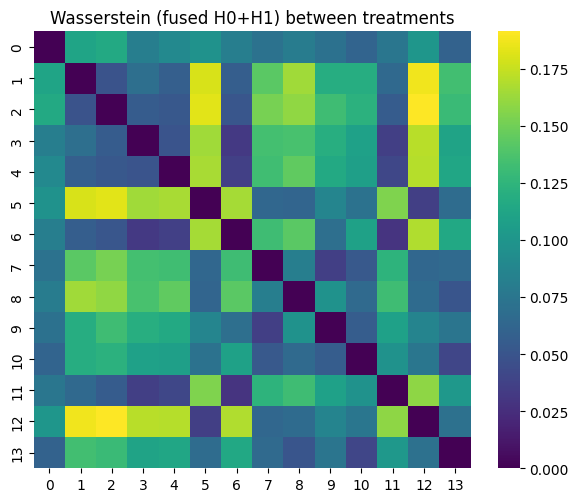

/Users/annasu/miniconda3/envs/cpsc6440/lib/python3.12/site-packages/sklearn/manifold/_mds.py:677: FutureWarning: The default value of `n_init` will change from 4 to 1 in 1.9.
  warnings.warn(


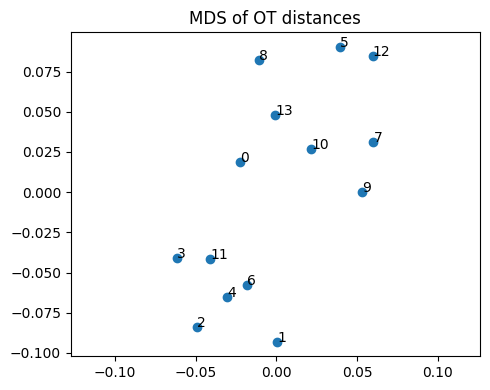

In [44]:
def group_diagrams_by_label(diags_per_pdo, y):
    """
    diags_per_pdo: list of dicts like {0: np.array([ [b,d], ... ]), 1: ...}
    y:             array-like of labels (e.g., treatment or response)
    returns:
      label_order: list of unique labels in deterministic order
      diags_by_label: dict[label] -> dict[dim] -> np.array([...,[b,d]])
                      concatenated across PDOs of the same label
    """
    lab2idxs = defaultdict(list)
    for i, lab in enumerate(y):
        lab2idxs[lab].append(i)

    label_order = sorted(lab2idxs.keys())
    diags_by_label = {}
    for lab in label_order:
        cat = {}
        for dim in (0, 1):
            chunks = []
            for i in lab2idxs[lab]:
                arr = diags_per_pdo[i].get(dim, np.zeros((0, 2), float))
                if arr is not None and arr.size > 0:
                    chunks.append(arr)
            if chunks:
                cat[dim] = np.vstack(chunks)
            else:
                cat[dim] = np.zeros((0, 2), float)
        diags_by_label[lab] = cat
    return label_order, diags_by_label

def _bd_to_bp(diag_bd):
    if diag_bd.size == 0:
        return diag_bd
    bp = diag_bd.copy()
    bp[:, 1] = np.maximum(diag_bd[:, 1] - diag_bd[:, 0], 0.0)
    return bp

def diagram_to_measure(diag_bd, eps=1e-12):
    """
    diag_bd: array [[b,d], ...]
    returns (supp, w): support in (b,p) and normalized weights ~ p
    """
    #TODO: Implement this function that returns the (b,p) pairs and normalized weights
    if diag_bd.size == 0 or diag_bd is None:
        return np.zeros((1, 2), float), np.ones((1), float) #2d cost matrix
    bp = _bd_to_bp(diag_bd) # convert to birth-persistence
    p = bp[:, 1].copy()
    p[p < 0] = 0  # ensure non-negative persistence
    if p.sum() == 0:
        w = np.ones((1), float)
    else:
        w = p / (p.sum() + eps)
    return bp, w

def w2_distance(supp1, w1, supp2, w2, *, sinkhorn_reg=None):
    """
    2-Wasserstein distance between two discrete measures over R^2 (b,p).
    Ground cost = squared Euclidean; returns sqrt(emd2).
    If sinkhorn_reg is not None (e.g., 1e-2), uses Sinkhorn2 for speed.
    """
    #TODO: Implement this function that calculates the 2-Wasserstein distance between
    M = ot.dist(supp1, supp2, metric='euclidean')**2  # squared Euclidean cost matrix
    if sinkhorn_reg is not None:
        emd2 = ot.sinkhorn2(w1, w2, M, reg=sinkhorn_reg)
    else:
        emd2 = ot.emd2(w1, w2, M)
    w2_dist = math.sqrt(emd2)
    return w2_dist

# ----------------------------
# 3) Pairwise W2 for H0, H1, and fused
# ----------------------------
def pairwise_w2_on_labels(diags_by_label, use_dims=(0, 1), weights=(1.0, 1.0), sinkhorn_reg=None):
    """
    diags_by_label: dict[label] -> {0: diag0_bd, 1: diag1_bd}
    use_dims: which homology dimensions to include
    weights: non-negative weights per dimension (same order as use_dims)
    sinkhorn_reg: None for exact; or small float (e.g., 1e-2) for Sinkhorn speedup

    returns:
      D_fused: [S,S] fused distance matrix
      D_per_dim: dict[dim] -> [S,S]
      label_order: list of labels for row/col order
    """
    label_order = sorted(diags_by_label.keys())
    S = len(label_order)

    # Precompute measures
    measures = {dim: [] for dim in use_dims}
    for lab in label_order:
        for dim in use_dims:
            supp, w = diagram_to_measure(diags_by_label[lab].get(dim, np.zeros((0, 2))))
            measures[dim].append((supp, w))

    D_per_dim = {}
    for dim in use_dims:
        D = np.zeros((S, S), float)
        for i, j in itertools.combinations(range(S), 2):
            d_ij = w2_distance(
                measures[dim][i][0], measures[dim][i][1],
                measures[dim][j][0], measures[dim][j][1],
                sinkhorn_reg=sinkhorn_reg
            )
            D[i, j] = D[j, i] = d_ij
        D_per_dim[dim] = D

    # Fuse via (weighted) Euclidean combination of per-dim distances
    w = np.array(weights, float)
    w = w / (w.sum() + 1e-12)
    # D_fused[i,j] = sqrt( sum_k w_k * D_k[i,j]^2 )
    Ds = [D_per_dim[d] for d in use_dims]
    D_fused = np.sqrt(np.tensordot(w, np.stack([D**2 for D in Ds], axis=0), axes=1))
    return D_fused, D_per_dim, label_order

label_order, diags_by_label = group_diagrams_by_label(diags_per_pdo, y)

D_fused, D_dims, label_order = pairwise_w2_on_labels(
    diags_by_label,
    use_dims=(0, 1),         # use H0 and H1
    weights=(1.0, 1.0),      # equal weight; tune if needed
    sinkhorn_reg=None        # or e.g. 1e-2 for Sinkhorn speedup
)

print("Labels order:", label_order)
print("Fused W2 distance matrix shape:", D_fused.shape)
print("H0/H1 matrices:", {k: v.shape for k, v in D_dims.items()})

plt.figure(figsize=(6, 5))
sns.heatmap(D_fused, xticklabels=label_order, yticklabels=label_order, square=True, cmap="viridis")
plt.title("Wasserstein (fused H0+H1) between treatments"); plt.tight_layout(); plt.show()

X_mds = MDS(n_components=2, dissimilarity='precomputed', random_state=0).fit_transform(D_fused)
plt.figure(figsize=(5, 4))
plt.scatter(X_mds[:,0], X_mds[:,1])
for i, lab in enumerate(label_order):
    plt.text(X_mds[i,0], X_mds[i,1], str(lab))
plt.title("MDS of OT distances"); plt.axis('equal'); plt.tight_layout(); plt.show()
